# Step 4: Regression - Predicting the Number of Shipping Days

**Goal:** when an order is placed, predict **how many days** it will take to ship (`Days for shipping (real)`).

This is the regression part of my project. Classification answered *"late or not?"*. Regression answers *"how many days?"*, which is useful for giving customers a realistic delivery date.

### Same rules as Step 3
- **No leakage:** only information known at order time. The public notebooks used `Late_delivery_risk` and `Delivery Status` as inputs to predict shipping days, and those are only known *after* delivery.
- **Time-based split:** train on Jan 2015 – Jun 2017, test on Jul 2017 – Jan 2018.
- **One row per order.**

### Two targets
1. **Actual shipping days** (0–6 days), the target from my proposal.
2. **Delay gap** = actual days − promised days, which tells the business *how far off the promise* is.

### Models
Baseline (overall average) → baseline per shipping mode → Linear Regression → Ridge Regression → Random Forest → XGBoost (tuned)

### Metrics
- **RMSE:** typical error in days; big mistakes count extra
- **MAE:** average error in days, easy to explain
- **R²:** share of the variation in shipping days the model explains (1 = perfect, 0 = no better than the average)
- **Within ±1 day:** share of orders where the prediction is at most 1 day off. This is the easiest one for business people to understand.

## 1. Setup

In [1]:
import sys, os, subprocess, time
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data (same loader as Steps 2–3)

In [2]:
def find_processed_dir():
    candidates = ["/content/drive/MyDrive/dataco-final-project/processed",
                  "/content/dataco-final-project/processed",
                  os.path.join("..", "data", "processed")]
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
    for c in candidates:
        if os.path.exists(os.path.join(c, "orders_clean.parquet")):
            return c
    return None

def rebuild_orders_from_raw():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    data_dir = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
    raw = pd.read_csv(os.path.join(data_dir, "DataCoSupplyChainDataset.csv"), encoding="latin-1")
    raw["order_date"] = pd.to_datetime(raw["order date (DateOrders)"])
    orders = (raw.groupby("Order Id")
                 .agg(order_date=("order_date", "first"),
                      customer_segment=("Customer Segment", "first"), market=("Market", "first"),
                      order_region=("Order Region", "first"), order_country=("Order Country", "first"),
                      shipping_mode=("Shipping Mode", "first"), payment_type=("Type", "first"),
                      days_scheduled=("Days for shipment (scheduled)", "first"),
                      days_real=("Days for shipping (real)", "first"),
                      late=("Late_delivery_risk", "first"),
                      delivery_status=("Delivery Status", "first"),
                      n_items=("Order Item Id", "count"), total_quantity=("Order Item Quantity", "sum"),
                      gross_sales=("Sales", "sum"), total_discount=("Order Item Discount", "sum"),
                      n_categories=("Category Name", "nunique"))
                 .reset_index().rename(columns={"Order Id": "order_id"}))
    orders["is_canceled"] = orders["delivery_status"].eq("Shipping canceled")
    orders["avg_discount_rate"] = orders["total_discount"] / orders["gross_sales"]
    return orders

proc = find_processed_dir()
if proc:
    orders = pd.read_parquet(os.path.join(proc, "orders_clean.parquet"))
    print("Loaded cleaned orders from:", proc)
else:
    print("Cleaned files not found - rebuilding from raw data (about 1 minute)...")
    orders = rebuild_orders_from_raw()

# Only shipped orders can be late or on time
df = orders[~orders["is_canceled"]].copy().sort_values("order_date").reset_index(drop=True)
print(f"Shipped orders: {len(df):,}   Late share: {df['late'].mean():.1%}")

Loaded cleaned orders from: ..\data\processed
Shipped orders: 62,897   Late share: 57.3%


## 3. Features (only what is known at order time) and the two targets

Inputs: ['shipping_mode', 'market', 'order_region', 'customer_segment', 'payment_type', 'order_weekday', 'order_hour', 'order_month', 'n_items', 'total_quantity', 'gross_sales', 'avg_discount_rate', 'n_categories', 'after_noon', 'same_day_after_noon']
Never used as inputs: days_real, late, delivery_status, delay_gap, profit


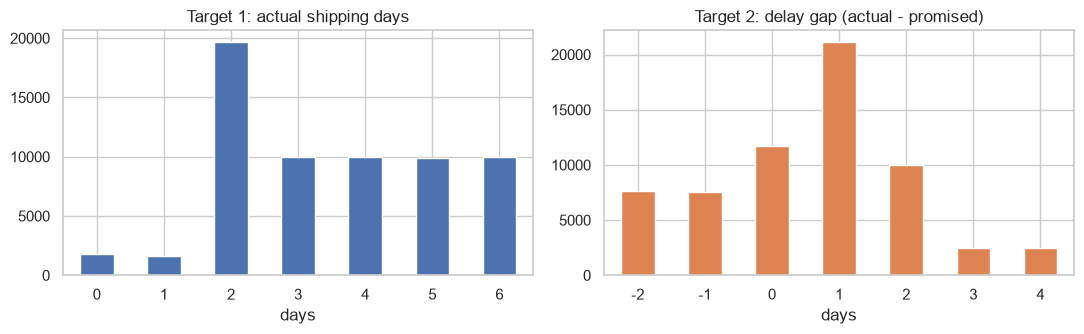

In [3]:
df["order_hour"] = df["order_date"].dt.hour
df["order_month"] = df["order_date"].dt.month
df["order_weekday"] = df["order_date"].dt.day_name()
df["after_noon"] = (df["order_hour"] >= 12).astype(int)
df["same_day_after_noon"] = ((df["shipping_mode"] == "Same Day") & (df["after_noon"] == 1)).astype(int)
df["delay_gap"] = df["days_real"] - df["days_scheduled"]

categorical = ["shipping_mode", "market", "order_region", "customer_segment", "payment_type", "order_weekday"]
numeric = ["order_hour", "order_month", "n_items", "total_quantity", "gross_sales", "avg_discount_rate", "n_categories"]
engineered = ["after_noon", "same_day_after_noon"]
features = categorical + numeric + engineered

print("Inputs:", features)
print("Never used as inputs: days_real, late, delivery_status, delay_gap, profit")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["days_real"].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_title("Target 1: actual shipping days"); axes[0].set_xlabel("days")
df["delay_gap"].value_counts().sort_index().plot.bar(ax=axes[1], color="#DD8452", rot=0)
axes[1].set_title("Target 2: delay gap (actual - promised)"); axes[1].set_xlabel("days")
plt.tight_layout(); plt.show()

## 4. Time-based split

In [4]:
cutoff = pd.Timestamp("2017-07-01")
train, test = df[df["order_date"] < cutoff], df[df["order_date"] >= cutoff]
print(f"Train: {len(train):,} orders   Test: {len(test):,} orders")
cv = TimeSeriesSplit(n_splits=5)

Train: 49,826 orders   Test: 13,071 orders


## 5. What is the best possible result? (the ceiling)
From Step 2 I know how shipping days behave:
- **First Class** always takes 2 days, which is perfectly predictable.
- **Same Day** takes 0 days before noon and 1 day after noon, which is also perfectly predictable.
- **Second and Standard Class** take 2, 3, 4, 5 or 6 days, evenly spread. Nothing in the data tells us which, so the best guess is the average (4 days), and the error can't be avoided.

So I can calculate the **lowest error any honest model can reach**, before training anything.

In [5]:
def ceiling_prediction(d, target):
    # Perfect knowledge of the patterns found in the EDA: per-mode average, plus the noon rule for Same Day
    group = d["shipping_mode"] + "_" + d["same_day_after_noon"].astype(str)
    means = train.assign(g=train["shipping_mode"] + "_" + train["same_day_after_noon"].astype(str)).groupby("g")[target].mean()
    return group.map(means).values

for target in ["days_real", "delay_gap"]:
    p = ceiling_prediction(test, target)
    print(f"{target:10s}  best possible RMSE = {np.sqrt(mean_squared_error(test[target], p)):.3f}   "
          f"R2 = {r2_score(test[target], p):.3f}")

days_real   best possible RMSE = 1.262   R2 = 0.394
delay_gap   best possible RMSE = 1.262   R2 = 0.293


**What I learned:** even a perfect model can only reach an **RMSE of about 1.26 days** and an **R² of about 0.39** for shipping days.
The remaining 61% of the variation is the random 2–6 day spread of Second and Standard Class orders. **No model can predict it from this data.**
This is my benchmark: a model that scores much better than this is probably cheating.

## 6. Train and evaluate all models

In [6]:
def make_preprocessor(cat_cols, num_cols):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])

def regression_metrics(name, y_true, y_pred):
    return {"model": name,
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred),
            "within_1_day": np.mean(np.abs(y_true - y_pred) <= 1)}

def build_models():
    return {
        "Baseline: overall average": DummyRegressor(strategy="mean"),
        "Linear Regression": Pipeline([("prep", make_preprocessor(categorical, numeric + engineered)),
                                       ("reg", LinearRegression())]),
        "Ridge Regression": Pipeline([("prep", make_preprocessor(categorical, numeric + engineered)),
                                      ("reg", Ridge(alpha=10.0))]),
        "Random Forest": Pipeline([("prep", make_preprocessor(categorical, numeric + engineered)),
                                   ("reg", RandomForestRegressor(n_estimators=100, min_samples_leaf=30, max_features=0.5,
                                                                 n_jobs=-1, random_state=RANDOM_STATE))]),
    }

def tuned_xgb(X, y):
    pipe = Pipeline([("prep", make_preprocessor(categorical, numeric + engineered)),
                     ("reg", XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE))])
    grid = {"reg__n_estimators": [100, 200, 400], "reg__max_depth": [2, 3, 4, 6],
            "reg__learning_rate": [0.03, 0.1, 0.2], "reg__subsample": [0.7, 0.9, 1.0],
            "reg__min_child_weight": [1, 5, 20]}
    search = RandomizedSearchCV(pipe, grid, n_iter=6, scoring="neg_root_mean_squared_error",
                                cv=cv, random_state=RANDOM_STATE, n_jobs=1).fit(X, y)
    print("  XGBoost best settings:", search.best_params_)
    return search.best_estimator_

all_results, fitted, preds = {}, {}, {}
for target in ["days_real", "delay_gap"]:
    print(f"Target: {target}")
    y_tr, y_te = train[target], test[target]
    rows = []
    rows.append(regression_metrics("Baseline: average per shipping mode (+ noon rule)", y_te,
                                   ceiling_prediction(test, target)))
    models = build_models()
    t0 = time.time()
    models["XGBoost (tuned)"] = tuned_xgb(train[features], y_tr)
    for name, model in models.items():
        model.fit(train[features], y_tr)
        p = model.predict(test[features])
        rows.append(regression_metrics(name, y_te.values, p))
        fitted[(target, name)], preds[(target, name)] = model, p
    print(f"  done in {time.time() - t0:.0f}s")
    all_results[target] = pd.DataFrame(rows).set_index("model").sort_values("RMSE")

print("\n=== Target 1: actual shipping days ===")
display(all_results["days_real"].round(3))

Target: days_real


  XGBoost best settings: {'reg__subsample': 0.7, 'reg__n_estimators': 100, 'reg__min_child_weight': 20, 'reg__max_depth': 2, 'reg__learning_rate': 0.1}


  done in 59s
Target: delay_gap


  XGBoost best settings: {'reg__subsample': 0.7, 'reg__n_estimators': 100, 'reg__min_child_weight': 20, 'reg__max_depth': 2, 'reg__learning_rate': 0.1}


  done in 55s

=== Target 1: actual shipping days ===


,RMSE,MAE,R2,within_1_day
model,,,,
Baseline: average per shipping mode (+ noon rule),1.262,0.954,0.394,0.523
Linear Regression,1.262,0.965,0.394,0.525
Ridge Regression,1.262,0.965,0.394,0.525
XGBoost (tuned),1.263,0.968,0.393,0.523
Random Forest,1.265,0.967,0.391,0.525
Baseline: overall average,1.621,1.423,-0.000,0.317


**What I learned (main result):**
- Using shipping mode cuts the error from **1.62 days** (always guess the overall average) to **1.26 days**, and R² goes from 0 to **0.39**.
- **Linear Regression, Ridge, Random Forest and XGBoost all reach RMSE ≈ 1.26 and R² ≈ 0.39, which is exactly the ceiling.** As in Step 3, the complex models don't beat the simple one, because there is no extra pattern to find.
- The simple "average per shipping mode" baseline is just as good. Linear Regression does the same thing in a more general way.
- Only about **52% of predictions are within ±1 day.** For Second and Standard Class the model predicts about 4 days, but the real answer is anywhere from 2 to 6, so 2-day and 6-day orders are always 2 days off.

## 7. Cross-validation (stability check on the training set)

In [7]:
cv_rows = []
for name in ["Linear Regression", "Ridge Regression", "Random Forest", "XGBoost (tuned)"]:
    model = fitted[("days_real", name)]
    scores = -cross_val_score(model, train[features], train["days_real"], cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
    cv_rows.append({"model": name, "cv_RMSE_mean": scores.mean(), "cv_RMSE_std": scores.std()})
pd.DataFrame(cv_rows).round(3)

,model,cv_RMSE_mean,cv_RMSE_std
0,Linear Regression,1.266,0.008
1,Ridge Regression,1.263,0.005
2,Random Forest,1.264,0.004
3,XGBoost (tuned),1.262,0.005


**What I learned:** cross-validated RMSE is about 1.26–1.27 for every model, with a very small spread (std ≤ 0.008). The test result is not luck, and none of the models overfits.

## 8. How good are the predictions? (actual vs predicted, and the errors)

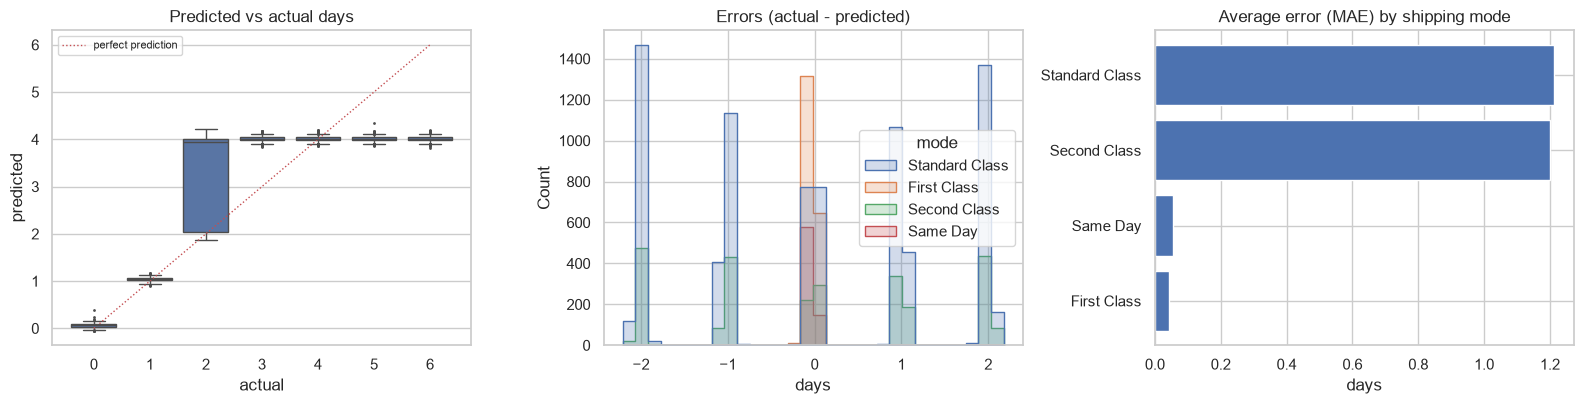

mode
First Class       0.042
Same Day          0.054
Second Class      1.200
Standard Class    1.212
Name: abs_err, dtype: float64

In [8]:
best = "XGBoost (tuned)"
p = preds[("days_real", best)]
y = test["days_real"].values

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_df = pd.DataFrame({"actual": y, "predicted": p, "mode": test["shipping_mode"].values})
sns.boxplot(data=plot_df, x="actual", y="predicted", ax=axes[0], color="#4C72B0", fliersize=1)
axes[0].plot([0, 6], [0, 6], "r:", lw=1, label="perfect prediction")
axes[0].set_title("Predicted vs actual days"); axes[0].legend(fontsize=8)

resid = y - p
sns.histplot(x=resid, hue=plot_df["mode"], bins=30, ax=axes[1], element="step", stat="count")
axes[1].set_title("Errors (actual - predicted)"); axes[1].set_xlabel("days")

err_by_mode = (plot_df.assign(abs_err=np.abs(resid)).groupby("mode")["abs_err"].mean().sort_values())
axes[2].barh(err_by_mode.index, err_by_mode.values, color="#4C72B0")
axes[2].set_title("Average error (MAE) by shipping mode"); axes[2].set_xlabel("days")
plt.tight_layout(); plt.show()
err_by_mode.round(3)

**What I learned:**
- **First Class and Same Day are predicted almost perfectly** (average error about 0.05 days).
- **Second and Standard Class have an average error of about 1.2 days.** The model always predicts about 4 days for them (see the flat boxes in the first chart), because nothing in the data separates a 2-day order from a 6-day order.
- **Business meaning:** for Second and Standard Class, the company should quote a **range ("2–6 business days")** instead of a single date. A single date will be wrong most of the time.

## 9. Which features matter?

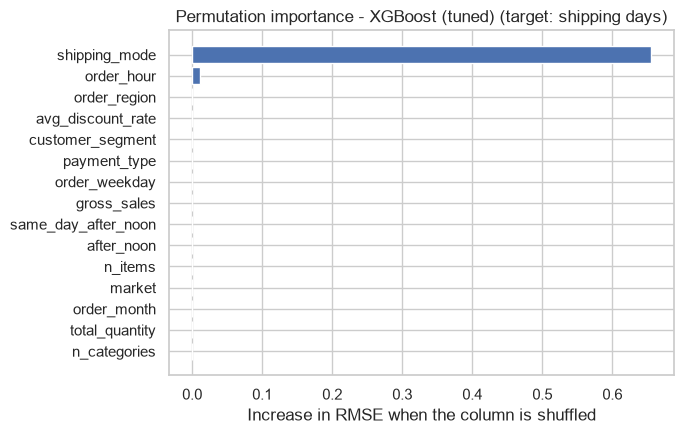

shipping_mode          0.6552
order_hour             0.0109
order_region           0.0002
avg_discount_rate      0.0001
customer_segment       0.0000
payment_type           0.0000
order_weekday          0.0000
gross_sales            0.0000
same_day_after_noon    0.0000
after_noon             0.0000
n_items               -0.0000
market                -0.0000
order_month           -0.0000
total_quantity        -0.0000
n_categories          -0.0001
dtype: float64

In [9]:
imp = permutation_importance(fitted[("days_real", best)], test[features], test["days_real"],
                             scoring="neg_root_mean_squared_error", n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=features).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color="#4C72B0")
ax.set_title(f"Permutation importance - {best} (target: shipping days)")
ax.set_xlabel("Increase in RMSE when the column is shuffled")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(4)

**What I learned:** shipping mode is by far the most important input, followed by order hour (the Same Day noon cut-off). Everything else is close to zero.
This is the third method (after the chi-square tests in Step 2 and classification importance in Step 3) that gives the same answer.
(The two engineered noon features show about zero here only because the trees already get the same information from `order_hour`. Shuffling one copy doesn't hurt when another copy is still there.)

## 10. Target 2: the delay gap (actual − promised days)

In [10]:
all_results["delay_gap"].round(3)

,RMSE,MAE,R2,within_1_day
model,,,,
Baseline: average per shipping mode (+ noon rule),1.262,0.954,0.293,0.523
Linear Regression,1.262,0.965,0.293,0.525
Ridge Regression,1.262,0.965,0.293,0.525
XGBoost (tuned),1.263,0.968,0.292,0.523
Random Forest,1.265,0.968,0.289,0.523
Baseline: overall average,1.501,1.212,-0.000,0.521


**What I learned:** the error is the **same 1.26 days**, because the promised days are fixed by the shipping mode, so subtracting them doesn't change what's unpredictable.
R² is lower (about 0.29) only because the delay gap varies less in total, not because the model is worse.
**Business view:** the model predicts First Class orders will be **1 day late** and Second Class about **2 days late**. That's another way of saying those promises need to change.

## 11. Proof of leakage (the regression version)
Some public notebooks predict shipping days while using `Late_delivery_risk` as an input. I repeat that with the same Random Forest to show the effect.

In [11]:
leaky_rf = Pipeline([("prep", make_preprocessor(categorical, numeric + engineered + ["late"])),
                     ("reg", RandomForestRegressor(n_estimators=100, min_samples_leaf=30, max_features=0.5,
                                                   n_jobs=-1, random_state=RANDOM_STATE))])
leaky_rf.fit(train[features + ["late"]], train["days_real"])
leak = pd.DataFrame([
    regression_metrics("Random Forest - honest", test["days_real"].values, preds[("days_real", "Random Forest")]),
    regression_metrics("Random Forest - LEAKY (uses the late flag)", test["days_real"].values,
                       leaky_rf.predict(test[features + ["late"]])),
]).set_index("model")
leak.round(3)

,RMSE,MAE,R2,within_1_day
model,,,,
Random Forest - honest,1.265,0.967,0.391,0.525
Random Forest - LEAKY (uses the late flag),0.708,0.524,0.809,0.802


**What I learned:** adding the late flag makes R² jump from **0.39 to about 0.81**, and "within ±1 day" from 52% to about 80%. That looks impressive, but the late flag is only known **after** delivery, so the model can't be used for real predictions.

## 12. Summary of Step 4

In [12]:
summary = all_results["days_real"][["RMSE", "MAE", "R2", "within_1_day"]].copy()
summary.columns = pd.MultiIndex.from_product([["Target 1: shipping days"], summary.columns])
gap = all_results["delay_gap"][["RMSE", "MAE", "R2", "within_1_day"]]
gap.columns = pd.MultiIndex.from_product([["Target 2: delay gap"], gap.columns])
summary.join(gap).round(3)

Target 1: shipping days  \
                                                                     RMSE   
model                                                                       
Baseline: average per shipping mode (+ noon rule)                   1.262   
Linear Regression                                                   1.262   
Ridge Regression                                                    1.262   
XGBoost (tuned)                                                     1.263   
Random Forest                                                       1.265   
Baseline: overall average                                           1.621   

                                                                              \
                                                     MAE     R2 within_1_day   
model                                                                          
Baseline: average per shipping mode (+ noon rule)  0.954  0.394        0.523   
Linear Regression                                  0.965  0.394        0.525   
Ridge Regression                                   0.965  0.394        0.525   
XGBoost (tuned)                                    0.968  0.393        0.523   
Random Forest                                      0.967  0.391        0.525   
Baseline: overall average                          1.423 -0.000        0.317   

                                                  Target 2: delay gap         \
                                                                 RMSE    MAE   
model                                                                          
Baseline: average per shipping mode (+ noon rule)               1.262  0.954   
Linear Regression                                               1.262  0.965   
Ridge Regression                                                1.262  0.965   
XGBoost (tuned)                                                 1.263  0.968   
Random Forest                                                   1.265  0.968   
Baseline: overall average                                       1.501  1.212   

                                                                       
                                                      R2 within_1_day  
model                                                                  
Baseline: average per shipping mode (+ noon rule)  0.293        0.523  
Linear Regression                                  0.293        0.525  
Ridge Regression                                   0.293        0.525  
XGBoost (tuned)                                    0.292        0.523  
Random Forest                                      0.289        0.523  
Baseline: overall average                         -0.000        0.521

### Key takeaways
| | RMSE (days) | MAE (days) | R² |
|---|---|---|---|
| Guess the overall average | 1.62 | 1.42 | 0.00 |
| Best honest models (Linear, Ridge, RF, XGBoost) | **1.26** | **0.97** | **0.39** |
| Calculated ceiling | 1.26 | - | 0.39 |
| *LEAKY Random Forest (not valid)* | *0.71* | *0.52* | *0.81* |

1. **All honest models reach the calculated ceiling.** RMSE ≈ 1.26 days and R² ≈ 0.39 is the best this data allows.
2. **Simple models are enough.** Linear Regression performed as well as XGBoost, and it's easier to explain.
3. **First Class and Same Day are predictable to the day. Second and Standard Class are not** (random 2–6 days).
4. **Recommendation:** quote **ranges** for Second/Standard Class, and fix the First/Second Class promises.

**Next:** Step 5, clustering: grouping countries by delivery performance and profit.